# Day - 1

In [11]:
print("Road Incident Risk Classification")
print("LearnDepth Academy LLP")
print("ML Task: Binary Classification")

Road Incident Risk Classification
LearnDepth Academy LLP
ML Task: Binary Classification


# PROJECT OBJECTIVE

The objective of this project is to develop a machine learning
model that classifies road observations into incident-risk
categories based on traffic density, speed variation, weather,
road characteristics and time.

# EXPECTED INPUTS

1. Traffic Density
2. Speed Variation
3. Weather
4. Road Characteristics
5. Time

# EXPECTED OUTPUT

The model predicts the incident risk category as:

High Risk
or
Low Risk

# RESEARCH DIRECTION

This project investigates how combinations of traffic and
environmental factors are associated with elevated road
incident risk.

# Day - 2

In [12]:
from google.colab import files
uploaded = files.upload()

Saving road_incident_risk_dataset to road_incident_risk_dataset (1)


In [13]:
import pandas as pd

In [14]:
df = pd.read_csv("road_incident_risk_dataset")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [15]:
df.head()

,traffic_density,speed_variation,weather,road_characteristics,time,incident_risk
0,61,10.3,Clear,Urban,1,Low
1,24,13.7,Clear,Urban,20,Low
2,81,10.7,Rain,Urban,14,High
3,70,18.9,Clear,Urban,19,High
4,30,1.9,Fog,Urban,17,Low


In [16]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 500
Number of columns: 6


In [17]:
print(df.columns.tolist())

['traffic_density', 'speed_variation', 'weather', 'road_characteristics', 'time', 'incident_risk']


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   traffic_density       500 non-null    int64  
 1   speed_variation       500 non-null    float64
 2   weather               500 non-null    object 
 3   road_characteristics  500 non-null    object 
 4   time                  500 non-null    int64  
 5   incident_risk         500 non-null    object 
dtypes: float64(1), int64(2), object(3)
memory usage: 23.6+ KB


In [19]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
traffic_density         0
speed_variation         0
weather                 0
road_characteristics    0
time                    0
incident_risk           0
dtype: int64


In [20]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [21]:
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (500, 6)


In [22]:
df.describe()

,traffic_density,speed_variation,time
count,500.000000,500.000000,500.000000
mean,53.624000,25.123400,11.678000
std,26.384292,13.856658,7.159108
min,10.000000,0.100000,0.000000
25%,31.000000,13.375000,5.000000
50%,54.500000,25.650000,12.000000
75%,73.250000,36.825000,18.000000
max,100.000000,49.900000,23.000000


In [23]:
print(df["incident_risk"].value_counts())

incident_risk
Low     250
High    250
Name: count, dtype: int64


# visualize class balance

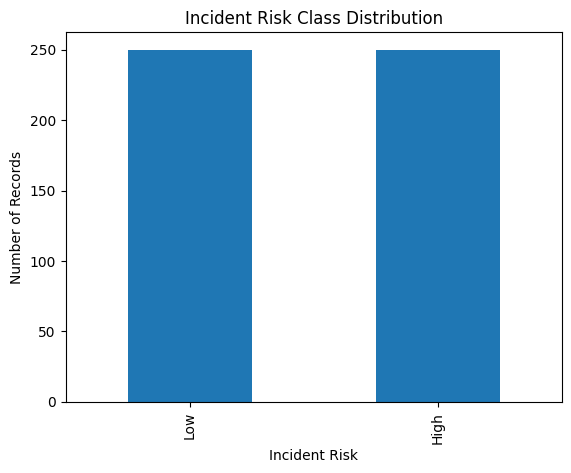

In [24]:
import matplotlib.pyplot as plt

df["incident_risk"].value_counts().plot(kind="bar")

plt.title("Incident Risk Class Distribution")
plt.xlabel("Incident Risk")
plt.ylabel("Number of Records")
plt.show()

In [25]:
print("Weather categories:")
print(df["weather"].value_counts())

print("\nRoad characteristics:")
print(df["road_characteristics"].value_counts())

Weather categories:
weather
Clear    259
Rain     129
Fog       69
Storm     43
Name: count, dtype: int64

Road characteristics:
road_characteristics
Urban           219
Highway         128
Rural            88
Intersection     65
Name: count, dtype: int64


In [26]:
df.to_csv("road_incident_risk_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# Day 3- EDA

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [28]:
df.head()

,traffic_density,speed_variation,weather,road_characteristics,time,incident_risk
0,61,10.3,Clear,Urban,1,Low
1,24,13.7,Clear,Urban,20,Low
2,81,10.7,Rain,Urban,14,High
3,70,18.9,Clear,Urban,19,High
4,30,1.9,Fog,Urban,17,Low


In [29]:
df.shape

(500, 6)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   traffic_density       500 non-null    int64  
 1   speed_variation       500 non-null    float64
 2   weather               500 non-null    object 
 3   road_characteristics  500 non-null    object 
 4   time                  500 non-null    int64  
 5   incident_risk         500 non-null    object 
dtypes: float64(1), int64(2), object(3)
memory usage: 23.6+ KB


# Traffic density distrubution

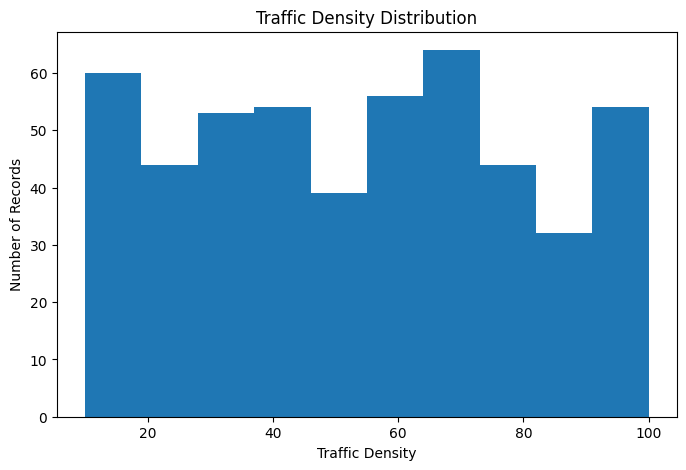

In [31]:
plt.figure(figsize=(8,5))

plt.hist(df["traffic_density"], bins=10)

plt.title("Traffic Density Distribution")
plt.xlabel("Traffic Density")
plt.ylabel("Number of Records")

plt.show()

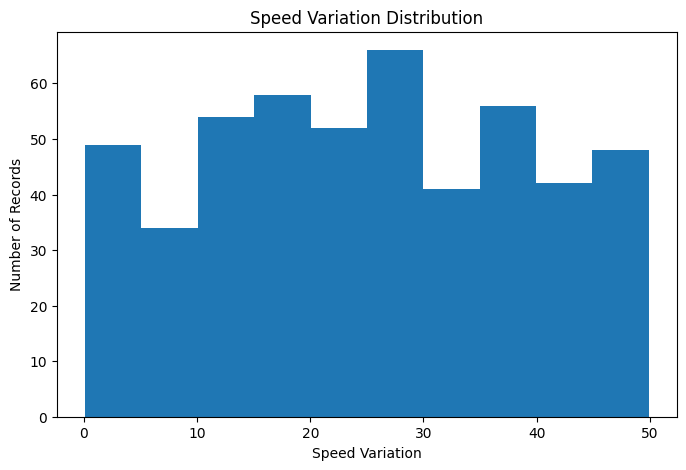

In [32]:
plt.figure(figsize=(8,5))

plt.hist(df["speed_variation"], bins=10)

plt.title("Speed Variation Distribution")
plt.xlabel("Speed Variation")
plt.ylabel("Number of Records")

plt.show()

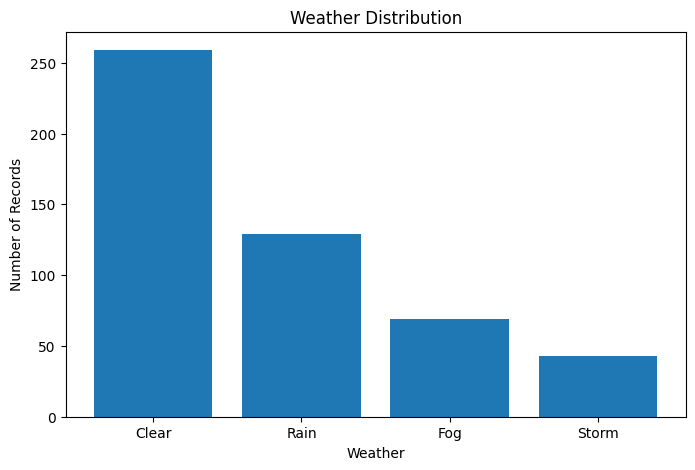

In [33]:
weather_counts = df["weather"].value_counts()

plt.figure(figsize=(8,5))

plt.bar(weather_counts.index, weather_counts.values)

plt.title("Weather Distribution")
plt.xlabel("Weather")
plt.ylabel("Number of Records")

plt.show()

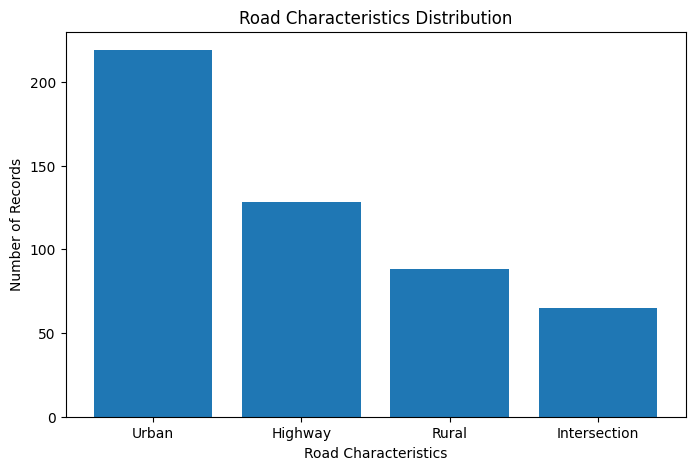

In [34]:
road_counts = df["road_characteristics"].value_counts()

plt.figure(figsize=(8,5))

plt.bar(road_counts.index, road_counts.values)

plt.title("Road Characteristics Distribution")
plt.xlabel("Road Characteristics")
plt.ylabel("Number of Records")

plt.show()

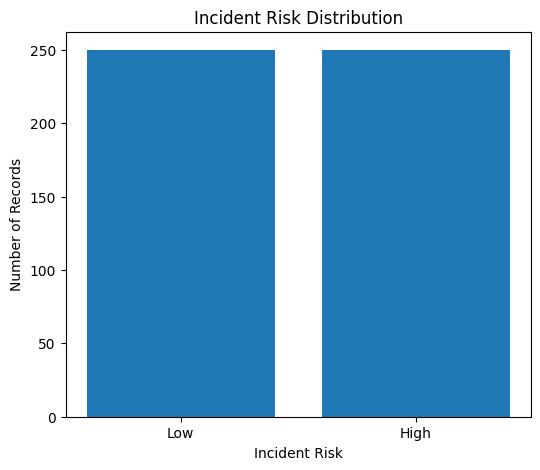

In [35]:
risk_counts = df["incident_risk"].value_counts()

plt.figure(figsize=(6,5))

plt.bar(risk_counts.index, risk_counts.values)

plt.title("Incident Risk Distribution")
plt.xlabel("Incident Risk")
plt.ylabel("Number of Records")

plt.show()

# weather vs incident risk

In [36]:
weather_risk = pd.crosstab(
    df["weather"],
    df["incident_risk"]
)

print(weather_risk)

incident_risk  High  Low
weather                 
Clear            80  179
Fog              48   21
Rain             84   45
Storm            38    5


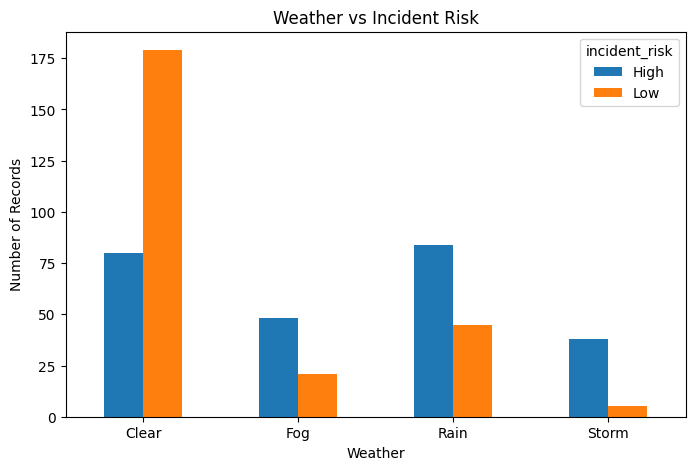

In [37]:
weather_risk.plot(kind="bar", figsize=(8,5))

plt.title("Weather vs Incident Risk")
plt.xlabel("Weather")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)
plt.show()

# road characteristics vs incident risk

In [38]:
road_risk = pd.crosstab(
    df["road_characteristics"],
    df["incident_risk"]
)

print(road_risk)

incident_risk         High  Low
road_characteristics           
Highway                 51   77
Intersection            40   25
Rural                   35   53
Urban                  124   95


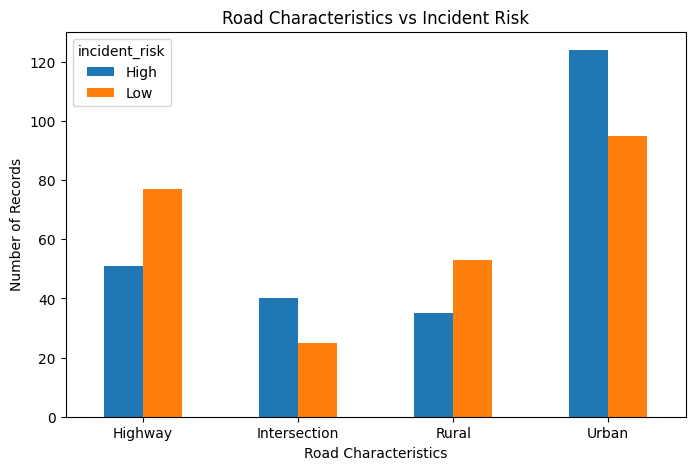

In [39]:
road_risk.plot(kind="bar", figsize=(8,5))

plt.title("Road Characteristics vs Incident Risk")
plt.xlabel("Road Characteristics")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)
plt.show()

# traffic density vs incident risk

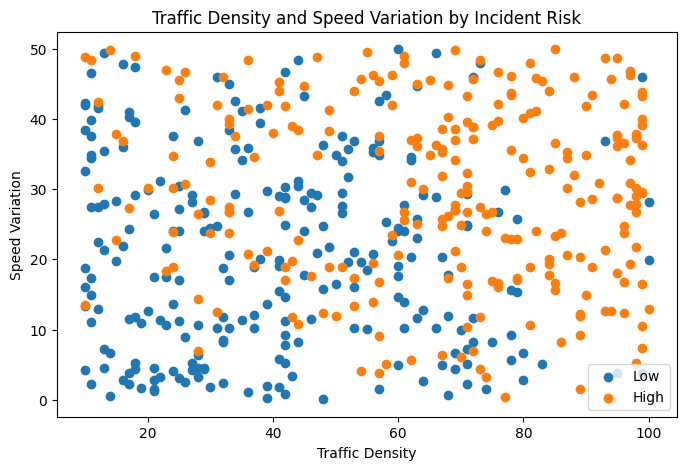

In [40]:
plt.figure(figsize=(8,5))

for risk in df["incident_risk"].unique():
    data = df[df["incident_risk"] == risk]
    plt.scatter(
        data["traffic_density"],
        data["speed_variation"],
        label=risk
    )

plt.title("Traffic Density and Speed Variation by Incident Risk")
plt.xlabel("Traffic Density")
plt.ylabel("Speed Variation")
plt.legend()

plt.show()

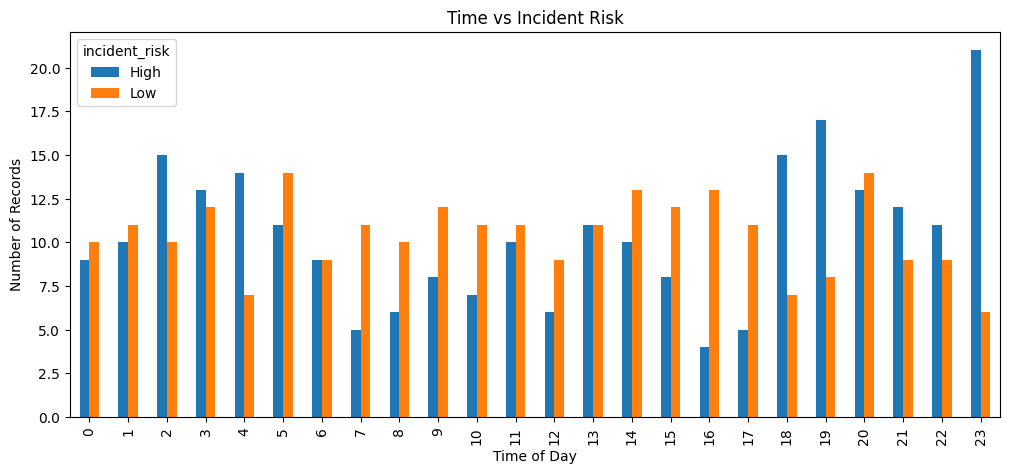

In [41]:
time_risk = pd.crosstab(
    df["time"],
    df["incident_risk"]
)

time_risk.plot(kind="bar", figsize=(12,5))

plt.title("Time vs Incident Risk")
plt.xlabel("Time of Day")
plt.ylabel("Number of Records")

plt.show()

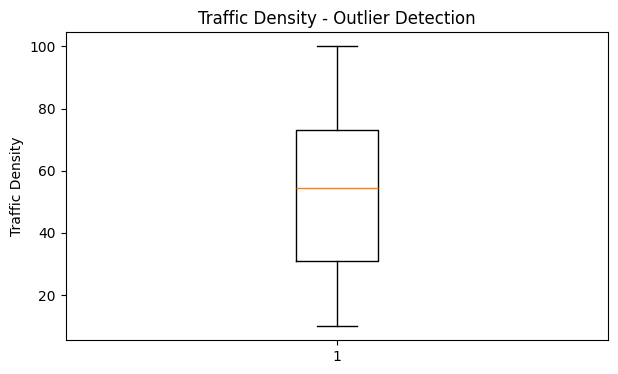

In [42]:
plt.figure(figsize=(7,4))

plt.boxplot(df["traffic_density"])

plt.title("Traffic Density - Outlier Detection")
plt.ylabel("Traffic Density")

plt.show()

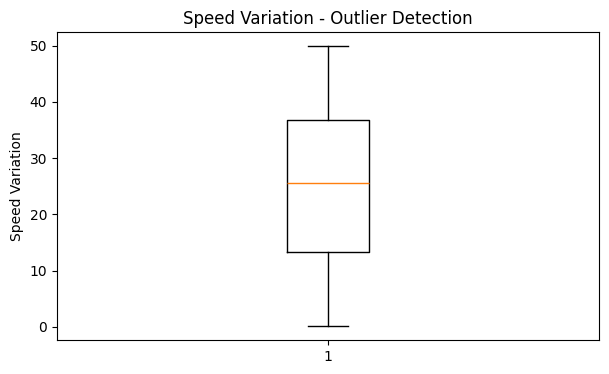

In [43]:
plt.figure(figsize=(7,4))

plt.boxplot(df["speed_variation"])

plt.title("Speed Variation - Outlier Detection")
plt.ylabel("Speed Variation")

plt.show()

# Numerical correlation

In [44]:
numeric_df = df[
    ["traffic_density", "speed_variation", "time"]
]

correlation = numeric_df.corr()

print(correlation)

                 traffic_density  speed_variation      time
traffic_density         1.000000         0.082272  0.037785
speed_variation         0.082272         1.000000  0.020261
time                    0.037785         0.020261  1.000000


# correlation heat map

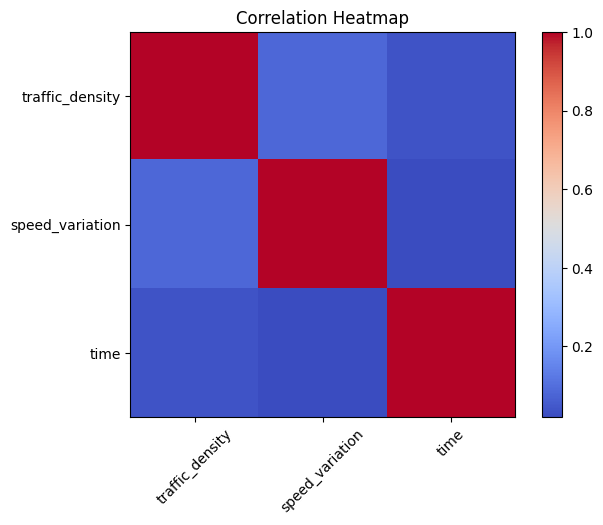

In [45]:
plt.figure(figsize=(7,5))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

plt.show()

In [46]:
print(df[
    ["traffic_density", "speed_variation", "time"]
].describe())

       traffic_density  speed_variation        time
count       500.000000       500.000000  500.000000
mean         53.624000        25.123400   11.678000
std          26.384292        13.856658    7.159108
min          10.000000         0.100000    0.000000
25%          31.000000        13.375000    5.000000
50%          54.500000        25.650000   12.000000
75%          73.250000        36.825000   18.000000
max         100.000000        49.900000   23.000000


In [47]:
print("Target column:", "incient_risk")

Target column: incient_risk


In [48]:
X = df.drop("incident_risk", axis=1)

print("Input features:")
print(X.columns.tolist())

Input features:
['traffic_density', 'speed_variation', 'weather', 'road_characteristics', 'time']


# EDA CONCLUSION

The dataset was explored using statistical analysis and
visualizations. Distributions of numerical and categorical
features were studied. Relationships between weather, road
characteristics, traffic density, speed variation, time and
incident risk were analyzed. Outliers and numerical correlations
were also investigated. The target classes were checked for
class balance and the dataset was examined for possible data
leakage.

# Day 4 - Model building

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [50]:
X = df.drop("incident_risk", axis=1)
y = df["incident_risk"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['traffic_density', 'speed_variation', 'weather', 'road_characteristics', 'time']

Target:
incident_risk


In [51]:
numeric_features = [
    "traffic_density",
    "speed_variation",
    "time"
]
categorical_features = [
    "weather",
    "road_characteristics"
]

In [52]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [53]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 5)
Testing data: (100, 5)


In [55]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [56]:
logistic_predictions = logistic_model.predict(X_test)

print(logistic_predictions[:20])

['Low' 'High' 'High' 'Low' 'Low' 'High' 'Low' 'High' 'High' 'High' 'Low'
 'High' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'High' 'High']


In [57]:
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

print("KNN trained successfully!")

KNN trained successfully!


In [58]:
knn_predictions = knn_model.predict(X_test)
print(knn_predictions[:20])

['Low' 'High' 'High' 'Low' 'Low' 'Low' 'Low' 'High' 'Low' 'High' 'Low'
 'High' 'Low' 'Low' 'Low' 'Low' 'Low' 'High' 'Low' 'High']


# Decision tree

In [59]:
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        max_depth=5
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [60]:
decision_tree_predictions = decision_tree_model.predict(X_test)

print(decision_tree_predictions[:20])

['Low' 'High' 'High' 'Low' 'Low' 'Low' 'Low' 'High' 'High' 'Low' 'Low'
 'High' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'High' 'High']


In [61]:
print("Logistic Regression:")
print(logistic_predictions[:10])

print("\nKNN:")
print(knn_predictions[:10])

print("\nDecision Tree:")
print(decision_tree_predictions[:10])

Logistic Regression:
['Low' 'High' 'High' 'Low' 'Low' 'High' 'Low' 'High' 'High' 'High']

KNN:
['Low' 'High' 'High' 'Low' 'Low' 'Low' 'Low' 'High' 'Low' 'High']

Decision Tree:
['Low' 'High' 'High' 'Low' 'Low' 'Low' 'Low' 'High' 'High' 'Low']


# check model probabilities

# Logistic regression

In [62]:
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# KNN

In [63]:
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

# Decision Tree

In [64]:
decision_tree_probabilities = decision_tree_model.predict_proba(X_test)[:, 1]

# Day 5 - Model evaluation

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report,
    roc_curve
)

import matplotlib.pyplot as plt
import pandas as pd

In [69]:
"High"
"Low"

'Low'

In [71]:
y_test_binary = (y_test == "High").astype(int)

logistic_pred_binary = (logistic_predictions == "High").astype(int)

knn_pred_binary = (knn_predictions == "High").astype(int)

decision_tree_pred_binary = (decision_tree_predictions == "High").astype(int)

print("Actual values:")
print(y_test_binary.head())

print("\nLogistic Regression:")
print(logistic_pred_binary[:10])

print("\nKNN:")
print(knn_pred_binary[:10])

print("\nDecision Tree:")
print(decision_tree_pred_binary[:10])

Actual values:
188    0
220    1
198    1
303    0
382    0
Name: incident_risk, dtype: int64

Logistic Regression:
[0 1 1 0 0 1 0 1 1 1]

KNN:
[0 1 1 0 0 0 0 1 0 1]

Decision Tree:
[0 1 1 0 0 0 0 1 1 0]


In [72]:
def high_risk_probability(model, X):
    class_index = list(model.named_steps["model"].classes_).index("High")
    return model.predict_proba(X)[:, class_index]

In [73]:
logistic_probabilities = high_risk_probability(
    logistic_model, X_test
)

knn_probabilities = high_risk_probability(
    knn_model, X_test
)

decision_tree_probabilities = high_risk_probability(
    decision_tree_model, X_test
)

print("Probability calculation completed.")

Probability calculation completed.


# Logistic regression evaluation

In [74]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    pos_label="High"
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    pos_label="High"
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    pos_label="High"
)

logistic_auc = roc_auc_score(
    y_test_binary,
    logistic_probabilities
)

print("LOGISTIC REGRESSION")
print("--------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-Score :", logistic_f1)
print("ROC-AUC  :", logistic_auc)

LOGISTIC REGRESSION
--------------------
Accuracy : 0.83
Precision: 0.851063829787234
Recall   : 0.8
F1-Score : 0.8247422680412371
ROC-AUC  : 0.8964000000000001


# KNN Evaluation

In [75]:
knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

knn_precision = precision_score(
    y_test,
    knn_predictions,
    pos_label="High"
)

knn_recall = recall_score(
    y_test,
    knn_predictions,
    pos_label="High"
)

knn_f1 = f1_score(
    y_test,
    knn_predictions,
    pos_label="High"
)

knn_auc = roc_auc_score(
    y_test_binary,
    knn_probabilities
)

print("KNN")
print("--------------------")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1-Score :", knn_f1)
print("ROC-AUC  :", knn_auc)

KNN
--------------------
Accuracy : 0.79
Precision: 0.8372093023255814
Recall   : 0.72
F1-Score : 0.7741935483870968
ROC-AUC  : 0.863


In [76]:
decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

decision_tree_precision = precision_score(
    y_test,
    decision_tree_predictions,
    pos_label="High"
)

decision_tree_recall = recall_score(
    y_test,
    decision_tree_predictions,
    pos_label="High"
)

decision_tree_f1 = f1_score(
    y_test,
    decision_tree_predictions,
    pos_label="High"
)

decision_tree_auc = roc_auc_score(
    y_test_binary,
    decision_tree_probabilities
)

print("DECISION TREE")
print("--------------------")
print("Accuracy :", decision_tree_accuracy)
print("Precision:", decision_tree_precision)
print("Recall   :", decision_tree_recall)
print("F1-Score :", decision_tree_f1)
print("ROC-AUC  :", decision_tree_auc)

DECISION TREE
--------------------
Accuracy : 0.75
Precision: 0.8378378378378378
Recall   : 0.62
F1-Score : 0.7126436781609196
ROC-AUC  : 0.8096000000000001


# Classification reports

# Logistics regression

In [77]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, logistic_predictions))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.85      0.80      0.82        50
         Low       0.81      0.86      0.83        50

    accuracy                           0.83       100
   macro avg       0.83      0.83      0.83       100
weighted avg       0.83      0.83      0.83       100



# KNN

In [78]:
print("KNN CLASSIFICATION REPORT")
print(classification_report(y_test, knn_predictions))

KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.84      0.72      0.77        50
         Low       0.75      0.86      0.80        50

    accuracy                           0.79       100
   macro avg       0.80      0.79      0.79       100
weighted avg       0.80      0.79      0.79       100



# Decision Tree

In [79]:
print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(y_test, decision_tree_predictions))

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.84      0.62      0.71        50
         Low       0.70      0.88      0.78        50

    accuracy                           0.75       100
   macro avg       0.77      0.75      0.75       100
weighted avg       0.77      0.75      0.75       100



# confusion matrix

#Logistic regression

In [80]:
cm_logistic = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=["Low", "High"]
)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

Logistic Regression Confusion Matrix:
[[43  7]
 [10 40]]


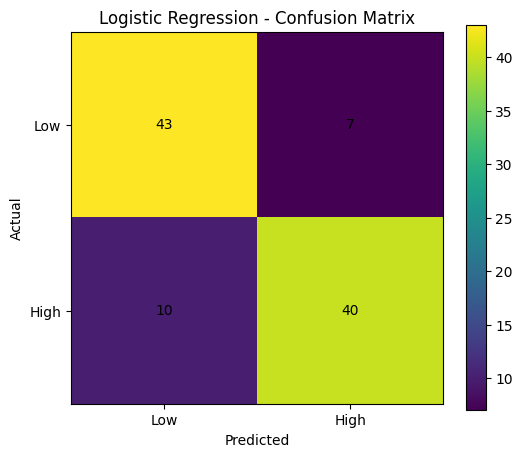

In [81]:
plt.figure(figsize=(6,5))

plt.imshow(cm_logistic)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_logistic[i, j],
                 ha="center",
                 va="center")

plt.show()

# KNN

In [82]:
cm_knn = confusion_matrix(
    y_test,
    knn_predictions,
    labels=["Low", "High"]
)

print("KNN Confusion Matrix:")
print(cm_knn)

KNN Confusion Matrix:
[[43  7]
 [14 36]]


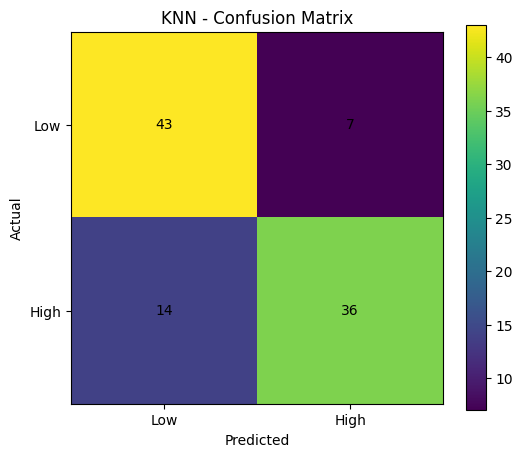

In [83]:
plt.figure(figsize=(6,5))

plt.imshow(cm_knn)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_knn[i, j],
                 ha="center",
                 va="center")

plt.show()

# Decision Tree

In [84]:
cm_tree = confusion_matrix(
    y_test,
    decision_tree_predictions,
    labels=["Low", "High"]
)

print("Decision Tree Confusion Matrix:")
print(cm_tree)

Decision Tree Confusion Matrix:
[[44  6]
 [19 31]]


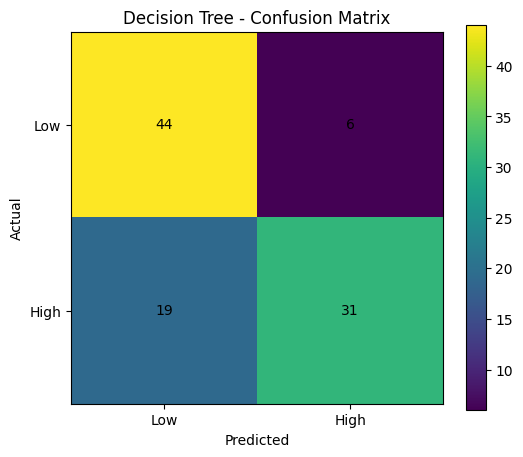

In [85]:
plt.figure(figsize=(6,5))

plt.imshow(cm_tree)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_tree[i, j],
                 ha="center",
                 va="center")

plt.show()

# model comparision table

In [86]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree"
    ],

    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        decision_tree_accuracy
    ],

    "Precision": [
        logistic_precision,
        knn_precision,
        decision_tree_precision
    ],

    "Recall": [
        logistic_recall,
        knn_recall,
        decision_tree_recall
    ],

    "F1-Score": [
        logistic_f1,
        knn_f1,
        decision_tree_f1
    ],

    "ROC-AUC": [
        logistic_auc,
        knn_auc,
        decision_tree_auc
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.83,0.851064,0.80,0.824742,0.8964
1,KNN,0.79,0.837209,0.72,0.774194,0.8630
2,Decision Tree,0.75,0.837838,0.62,0.712644,0.8096


# ROC curve

In [87]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test_binary,
    logistic_probabilities
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test_binary,
    knn_probabilities
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test_binary,
    decision_tree_probabilities
)

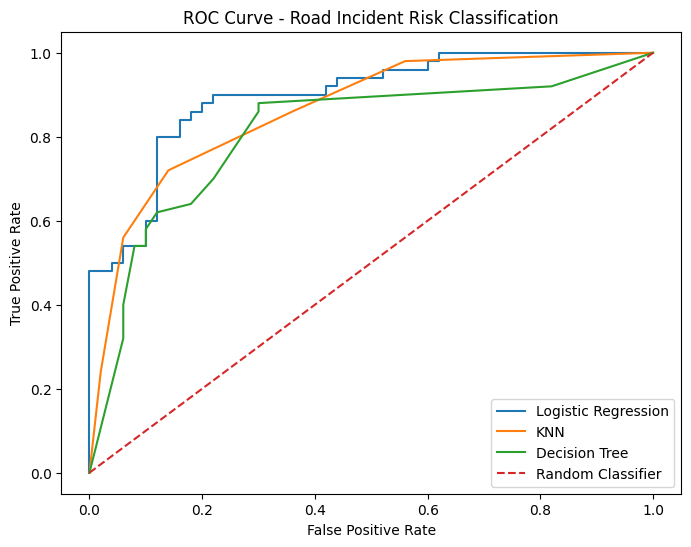

In [88]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label="Logistic Regression"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label="KNN"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label="Decision Tree"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Road Incident Risk Classification")

plt.legend()

plt.show()

# Evaluation results

In [89]:
comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


# Day 6 - model improvement and hyperparameter tunning

In [90]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

print("Hyperparameter tuning libraries imported successfully!")

Hyperparameter tuning libraries imported successfully!


In [91]:
high_risk_f1 = make_scorer(
    f1_score,
    pos_label="High"
)

print("F1 scoring configured for High Risk.")

F1 scoring configured for High Risk.


# Tune logistic regression

In [92]:
logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

logistic_parameters = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    logistic_parameters,
    cv=5,
    scoring=high_risk_f1,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("Best F1-score:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'model__C': 10}
Best F1-score:
0.8250479502057889


# Tune KNN

In [93]:
knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_parameters = {
    "model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_parameters,
    cv=5,
    scoring=high_risk_f1,
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("Best F1-score:")
print(knn_grid.best_score_)

Best KNN parameters:
{'model__n_neighbors': 5, 'model__weights': 'distance'}
Best F1-score:
0.7987002394142109


# Tune decision tree

In [94]:
knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_parameters = {
    "model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_parameters,
    cv=5,
    scoring=high_risk_f1,
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("Best F1-score:")
print(knn_grid.best_score_)

Best KNN parameters:
{'model__n_neighbors': 5, 'model__weights': 'distance'}
Best F1-score:
0.7987002394142109


# store the tuned models

In [96]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_parameters = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

tree_grid = GridSearchCV(
    tree_pipeline,
    tree_parameters,
    cv=5,
    scoring=high_risk_f1,
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(tree_grid.best_params_)

print("Best F1-score:")
print(tree_grid.best_score_)

Best Decision Tree parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}
Best F1-score:
0.7975438125093298


In [97]:
tuned_logistic_model = logistic_grid.best_estimator_

tuned_knn_model = knn_grid.best_estimator_

tuned_decision_tree_model = tree_grid.best_estimator_

print("Tuned models created successfully!")

Tuned models created successfully!


In [98]:
tuned_logistic_predictions = tuned_logistic_model.predict(X_test)

tuned_knn_predictions = tuned_knn_model.predict(X_test)

tuned_tree_predictions = tuned_decision_tree_model.predict(X_test)

print("Tuned model predictions completed successfully!")

Tuned model predictions completed successfully!


# Evaluate Tuned logistic regression

In [99]:
tuned_logistic_accuracy = accuracy_score(
    y_test,
    tuned_logistic_predictions
)

tuned_logistic_precision = precision_score(
    y_test,
    tuned_logistic_predictions,
    pos_label="High"
)

tuned_logistic_recall = recall_score(
    y_test,
    tuned_logistic_predictions,
    pos_label="High"
)

tuned_logistic_f1 = f1_score(
    y_test,
    tuned_logistic_predictions,
    pos_label="High"
)

print("TUNED LOGISTIC REGRESSION")
print("-------------------------")
print("Accuracy :", tuned_logistic_accuracy)
print("Precision:", tuned_logistic_precision)
print("Recall   :", tuned_logistic_recall)
print("F1-Score :", tuned_logistic_f1)

TUNED LOGISTIC REGRESSION
-------------------------
Accuracy : 0.83
Precision: 0.851063829787234
Recall   : 0.8
F1-Score : 0.8247422680412371


# Evaluate tuned KNN

In [100]:
tuned_knn_accuracy = accuracy_score(
    y_test,
    tuned_knn_predictions
)

tuned_knn_precision = precision_score(
    y_test,
    tuned_knn_predictions,
    pos_label="High"
)

tuned_knn_recall = recall_score(
    y_test,
    tuned_knn_predictions,
    pos_label="High"
)

tuned_knn_f1 = f1_score(
    y_test,
    tuned_knn_predictions,
    pos_label="High"
)

print("TUNED KNN")
print("-------------------------")
print("Accuracy :", tuned_knn_accuracy)
print("Precision:", tuned_knn_precision)
print("Recall   :", tuned_knn_recall)
print("F1-Score :", tuned_knn_f1)

TUNED KNN
-------------------------
Accuracy : 0.8
Precision: 0.8409090909090909
Recall   : 0.74
F1-Score : 0.7872340425531915


# Evaluate tuned decision tree

In [101]:
tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_predictions
)

tuned_tree_precision = precision_score(
    y_test,
    tuned_tree_predictions,
    pos_label="High"
)

tuned_tree_recall = recall_score(
    y_test,
    tuned_tree_predictions,
    pos_label="High"
)

tuned_tree_f1 = f1_score(
    y_test,
    tuned_tree_predictions,
    pos_label="High"
)

print("TUNED DECISION TREE")
print("-------------------------")
print("Accuracy :", tuned_tree_accuracy)
print("Precision:", tuned_tree_precision)
print("Recall   :", tuned_tree_recall)
print("F1-Score :", tuned_tree_f1)

TUNED DECISION TREE
-------------------------
Accuracy : 0.8
Precision: 0.8125
Recall   : 0.78
F1-Score : 0.7959183673469388


# compare original vs tuned

In [102]:
improvement_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Tuned Logistic Regression",
        "KNN",
        "Tuned KNN",
        "Decision Tree",
        "Tuned Decision Tree"
    ],

    "Accuracy": [
        logistic_accuracy,
        tuned_logistic_accuracy,
        knn_accuracy,
        tuned_knn_accuracy,
        decision_tree_accuracy,
        tuned_tree_accuracy
    ],

    "Precision": [
        logistic_precision,
        tuned_logistic_precision,
        knn_precision,
        tuned_knn_precision,
        decision_tree_precision,
        tuned_tree_precision
    ],

    "Recall": [
        logistic_recall,
        tuned_logistic_recall,
        knn_recall,
        tuned_knn_recall,
        decision_tree_recall,
        tuned_tree_recall
    ],

    "F1-Score": [
        logistic_f1,
        tuned_logistic_f1,
        knn_f1,
        tuned_knn_f1,
        decision_tree_f1,
        tuned_tree_f1
    ]
})

improvement_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.83,0.851064,0.80,0.824742
1,Tuned Logistic Regression,0.83,0.851064,0.80,0.824742
2,KNN,0.79,0.837209,0.72,0.774194
3,Tuned KNN,0.80,0.840909,0.74,0.787234
4,Decision Tree,0.75,0.837838,0.62,0.712644
5,Tuned Decision Tree,0.80,0.812500,0.78,0.795918


# Feature importance

In [103]:
feature_names = (
    tuned_decision_tree_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

feature_importance = (
    tuned_decision_tree_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
0,numeric__traffic_density,0.444445
1,numeric__speed_variation,0.162320
3,categorical__weather_Clear,0.143487
2,numeric__time,0.132418
10,categorical__road_characteristics_Urban,0.052784
5,categorical__weather_Rain,0.027798
9,categorical__road_characteristics_Rural,0.026291
8,categorical__road_characteristics_Intersection,0.007872
7,categorical__road_characteristics_Highway,0.002585
6,categorical__weather_Storm,0.000000


# Feature importance graph

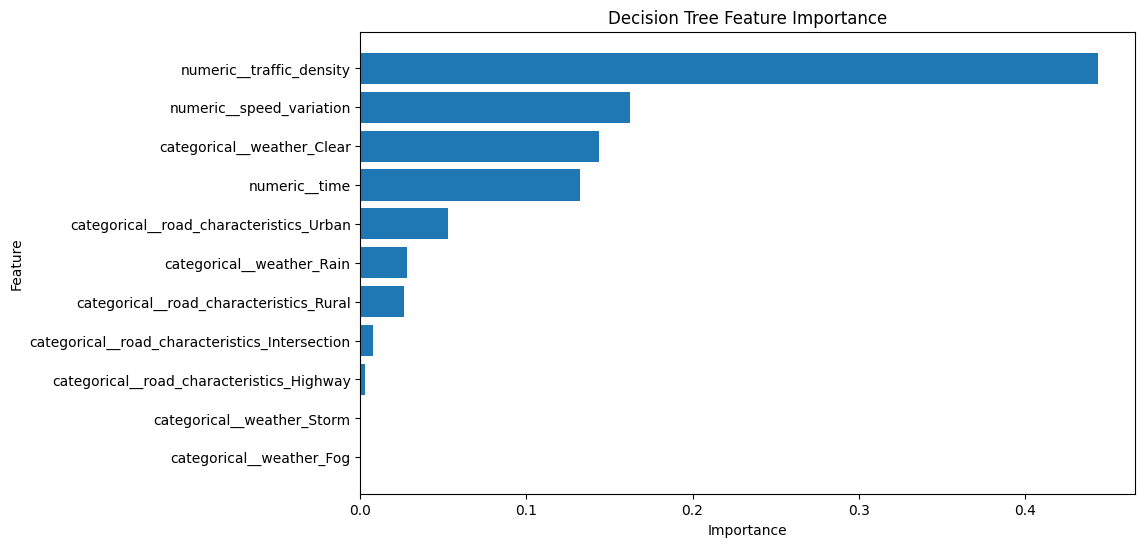

In [104]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")

plt.gca().invert_yaxis()

plt.show()

# day 6 results

In [105]:
improvement_results.to_csv(
    "model_improvement_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("Day 6 results saved successfully!")

Day 6 results saved successfully!


# streamlit model

In [106]:
import joblib

joblib.dump(
    tuned_decision_tree_model,
    "road_incident_risk_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


# day 7 - stramlit web application

In [107]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 40.2 MB/s eta 0:00:00


In [132]:
import os

print(os.path.exists("road_incident_risk_model.pkl"))

True


In [109]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("road_incident_risk_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Road Incident Risk Classification",
    page_icon="🚗",
    layout="centered"
)

# Title
st.title("🚗 Road Incident Risk Classification")

st.write(
    "Enter the road and traffic conditions below "
    "to predict the incident risk."
)

st.divider()

# Input 1 - Traffic Density
traffic_density = st.number_input(
    "Traffic Density",
    min_value=0.0,
    max_value=100.0,
    value=50.0
)

# Input 2 - Speed Variation
speed_variation = st.number_input(
    "Speed Variation",
    min_value=0.0,
    max_value=50.0,
    value=10.0
)

# Input 3 - Weather
weather = st.selectbox(
    "Weather",
    [
        "Clear",
        "Rainy",
        "Foggy",
        "Stormy"
    ]
)

# Input 4 - Road Characteristics
road_characteristics = st.selectbox(
    "Road Characteristics",
    [
        "Good",
        "Moderate",
        "Poor"
    ]
)

# Input 5 - Time
time = st.number_input(
    "Time of Day",
    min_value=0,
    max_value=23,
    value=12,
    step=1
)

st.divider()

# Prediction button
if st.button("🔍 Predict Incident Risk"):

    input_data = pd.DataFrame({
        "traffic_density": [traffic_density],
        "speed_variation": [speed_variation],
        "weather": [weather],
        "road_characteristics": [road_characteristics],
        "time": [time]
    })

    prediction = model.predict(input_data)[0]

    # Display prediction
    if prediction == "High":
        st.error("⚠️ HIGH RISK")
        st.write(
            "The model predicts a high incident-risk condition."
        )
    else:
        st.success("✅ LOW RISK")
        st.write(
            "The model predicts a low incident-risk condition."
        )

    # Probability
    probabilities = model.predict_proba(input_data)[0]

    classes = list(
        model.named_steps["model"].classes_
    )

    high_index = classes.index("High")
    low_index = classes.index("Low")

    high_probability = probabilities[high_index] * 100
    low_probability = probabilities[low_index] * 100

    st.write(
        f"High Risk Probability: {high_probability:.2f}%"
    )

    st.write(
        f"Low Risk Probability: {low_probability:.2f}%"
    )

Writing app.py


In [110]:
!ls -l app.py

-rw-r--r-- 1 root root 2338 Sep 30 07:00 app.py


In [111]:
%%writefile requirements.txt

streamlit
pandas
scikit-learn
joblib

Writing requirements.txt


In [112]:
!ls

 app.py				  road_incident_risk_cleaned.csv
 feature_importance_results.csv   road_incident_risk_dataset
 model_comparison_results.csv	 'road_incident_risk_dataset (1)'
 model_improvement_results.csv	  road_incident_risk_model.pkl
 requirements.txt		  sample_data


In [113]:
!streamlit run app.py &>/content/streamlit.log &

In [114]:
!cat /content/streamlit.log



2026-09-30 07:02:40.575 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.229.160.181:8501



In [133]:
test_input = pd.DataFrame({
    "traffic_density": [80],
    "speed_variation": [20],
    "weather": ["Rainy"],
    "road_characteristics": ["Poor"],
    "time": [18]
})

test_prediction = tuned_decision_tree_model.predict(test_input)

print("Predicted Risk:", test_prediction[0])

Predicted Risk: High


In [134]:
test_input_2 = pd.DataFrame({
    "traffic_density": [20],
    "speed_variation": [5],
    "weather": ["Clear"],
    "road_characteristics": ["Good"],
    "time": [11]
})

test_prediction_2 = tuned_decision_tree_model.predict(
    test_input_2
)

print("Predicted Risk:", test_prediction_2[0])

Predicted Risk: Low


# day 7 documentation
STREAMLIT APPLICATION

A Streamlit-based web application was developed to provide
an interactive interface for the Road Incident Risk
Classification model.

The application accepts traffic density, speed variation,
weather, road characteristics and time as inputs.

The trained machine learning model processes these inputs
and predicts the road incident risk as High Risk or Low Risk.

The application also displays the predicted probability
for the High Risk and Low Risk classes.

# Day 8 - Integration and testing

In [118]:
import os

required_files = [
    "road_incident_risk_dataset.csv",
    "road_incident_risk_cleaned.csv",
    "app.py",
    "road_incident_risk_model.pkl",
    "requirements.txt"
]

print("PROJECT FILE CHECK")
print("------------------")

for file in required_files:
    if os.path.exists(file):
        print("✅", file, "- Found")
    else:
        print("❌", file, "- Missing")

PROJECT FILE CHECK
------------------
❌ road_incident_risk_dataset.csv - Missing
✅ road_incident_risk_cleaned.csv - Found
✅ app.py - Found
✅ road_incident_risk_model.pkl - Found
✅ requirements.txt - Found


# test the model loading

In [119]:
import joblib

loaded_model = joblib.load(
    "road_incident_risk_model.pkl"
)

print("✅ Model loaded successfully!")

✅ Model loaded successfully!


# test a high risk input

In [120]:
high_risk_test = pd.DataFrame({
    "traffic_density": [90],
    "speed_variation": [25],
    "weather": ["Rainy"],
    "road_characteristics": ["Poor"],
    "time": [18]
})

prediction = loaded_model.predict(high_risk_test)

print("Prediction:", prediction[0])

Prediction: High


# testing another input

In [121]:
normal_test = pd.DataFrame({
    "traffic_density": [20],
    "speed_variation": [5],
    "weather": ["Clear"],
    "road_characteristics": ["Good"],
    "time": [11]
})

prediction = loaded_model.predict(normal_test)

print("Prediction:", prediction[0])

Prediction: Low


# testing all possible categories

In [122]:
weather_tests = ["Clear", "Rainy", "Foggy", "Stormy"]

for weather_value in weather_tests:

    test_data = pd.DataFrame({
        "traffic_density": [50],
        "speed_variation": [10],
        "weather": [weather_value],
        "road_characteristics": ["Moderate"],
        "time": [12]
    })

    prediction = loaded_model.predict(test_data)[0]

    print(weather_value, "→", prediction)

Clear → Low
Rainy → High
Foggy → High
Stormy → High


# testing all road conditions

In [123]:
road_tests = ["Good", "Moderate", "Poor"]

for road_value in road_tests:

    test_data = pd.DataFrame({
        "traffic_density": [50],
        "speed_variation": [10],
        "weather": ["Clear"],
        "road_characteristics": [road_value],
        "time": [12]
    })

    prediction = loaded_model.predict(test_data)[0]

    print(road_value, "→", prediction)

Good → Low
Moderate → Low
Poor → Low


In [124]:
time_tests = [6, 9, 12, 18, 21]

for time_value in time_tests:

    test_data = pd.DataFrame({
        "traffic_density": [60],
        "speed_variation": [15],
        "weather": ["Clear"],
        "road_characteristics": ["Moderate"],
        "time": [time_value]
    })

    prediction = loaded_model.predict(test_data)[0]

    print(
        "Time:",
        time_value,
        "→",
        prediction
    )

Time: 6 → Low
Time: 9 → Low
Time: 12 → Low
Time: 18 → Low
Time: 21 → Low


# test probability output

In [125]:
test_data = pd.DataFrame({
    "traffic_density": [70],
    "speed_variation": [15],
    "weather": ["Rainy"],
    "road_characteristics": ["Poor"],
    "time": [18]
})

probabilities = loaded_model.predict_proba(test_data)[0]

classes = list(
    loaded_model.named_steps["model"].classes_
)

for class_name, probability in zip(
    classes,
    probabilities
):
    print(
        class_name,
        "Probability:",
        round(probability * 100, 2),
        "%"
    )

High Probability: 100.0 %
Low Probability: 0.0 %


# verify the probabilities

In [126]:
total_probability = probabilities.sum()

print(
    "Total probability:",
    round(total_probability, 4)
)

Total probability: 1.0


# checking stream lite application code

In [127]:
with open("app.py", "r") as file:
    app_code = file.read()

print(app_code[:2000])


import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("road_incident_risk_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Road Incident Risk Classification",
    page_icon="🚗",
    layout="centered"
)

# Title
st.title("🚗 Road Incident Risk Classification")

st.write(
    "Enter the road and traffic conditions below "
    "to predict the incident risk."
)

st.divider()

# Input 1 - Traffic Density
traffic_density = st.number_input(
    "Traffic Density",
    min_value=0.0,
    max_value=100.0,
    value=50.0
)

# Input 2 - Speed Variation
speed_variation = st.number_input(
    "Speed Variation",
    min_value=0.0,
    max_value=50.0,
    value=10.0
)

# Input 3 - Weather
weather = st.selectbox(
    "Weather",
    [
        "Clear",
        "Rainy",
        "Foggy",
        "Stormy"
    ]
)

# Input 4 - Road Characteristics
road_characteristics = st.selectbox(
    "Road Characteristics",
    [
        "Good",
        "M

# checking requirements

In [128]:
with open("requirements.txt", "r") as file:
    requirements = file.read()

print(requirements)


streamlit
pandas
scikit-learn
joblib



# final integration test

In [129]:
final_test = pd.DataFrame({
    "traffic_density": [75],
    "speed_variation": [18],
    "weather": ["Rainy"],
    "road_characteristics": ["Poor"],
    "time": [18]
})

final_prediction = loaded_model.predict(
    final_test
)[0]

final_probabilities = loaded_model.predict_proba(
    final_test
)[0]

classes = list(
    loaded_model.named_steps["model"].classes_
)

print("FINAL INTEGRATION TEST")
print("----------------------")

print("Input:")
print(final_test)

print("\nPredicted Risk:", final_prediction)

print("\nProbabilities:")

for class_name, probability in zip(
    classes,
    final_probabilities
):
    print(
        class_name,
        ":",
        round(probability * 100, 2),
        "%"
    )

print("\n✅ Integration test completed!")

FINAL INTEGRATION TEST
----------------------
Input:
   traffic_density  speed_variation weather road_characteristics  time
0               75               18   Rainy                 Poor    18

Predicted Risk: High

Probabilities:
High : 100.0 %
Low : 0.0 %

✅ Integration test completed!


# creating a testing summary
INTEGRATION AND TESTING

The trained machine learning model was integrated with the
Streamlit application.

The saved model was successfully loaded and tested using
different combinations of traffic density, speed variation,
weather, road characteristics and time.

Prediction outputs and class probabilities were verified.

The Streamlit application files and required dependencies
were also checked to ensure that the project is ready for
deployment and demonstration.